# 02 – Визуализация и анализ данных Северной Америки

Графики строятся по отдельным ячейкам. Каждый график сопровождается вопросом, результатом и ограничениями интерпретации.

Основание: [аудит 01](01_regional_quality.ipynb). Период наблюдений – 2019 год. Исходные записи сохраняются, изображения отображаются внутри ноутбука.

Температурные аномалии и проверка METAR: [ноутбук 03](04_temperature_and_metar.ipynb).


## Достаточность покрытия для анализа редкого события

Покрытие оценивается по объему наблюдений и событий, точности частоты, полноте периода и условий.

$$
\widehat p_i=\frac{k_i}{n_i},\qquad
\Delta_i=\max(\widehat p_i-L_i,\;U_i-\widehat p_i),\qquad
\boxed{\Delta_i\leq0{,}002}
$$

$[L_i,U_i]$ – двусторонний 95% интервал Уилсона. Допуск 0,002 соответствует 0,2 процентного пункта и согласован 07.10.2026. Условие определяет достаточную абсолютную точность аэропортной оценки, но не подтверждает полноту покрытия или правильность разметки.

Критерий рассчитан для всех исходных аэропортов. Он выполняется для 46 из 74 групп. В текущем CSV 46 из 57 аэропортов проходят допуск; остальные 11 сохраняются до отдельного решения. Параметр согласован после предварительного анализа, отбор является ретроспективным.

Отсутствие событий не означает нулевую вероятность. Зависимость наблюдений ограничивает применимость биномиальной оценки. Невыполнение критерия не является автоматическим основанием удаления исходных записей.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Находим папку проекта независимо от места запуска ноутбука
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "north_america" / "reports" / "country_summary.csv").exists())
ORANGE = "#FF6B00"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 16,
    "text.color": "#253047", "axes.labelcolor": "#536079",
    "xtick.color": "#536079", "ytick.color": "#253047",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.dpi": 130,
})


## График 1. Географический состав выборки

**Вопрос:** насколько равномерно представлены страны и территории в региональной выборке?

Единица учета – запись о посадке, которая может включать несколько попыток захода. Объем выборки не равен полному объему воздушного движения.


In [2]:
countries = pd.read_csv(ROOT / "north_america" / "reports" / "country_summary.csv")
countries = countries.sort_values("rows", ascending=False).reset_index(drop=True)
countries["sample_percent"] = countries["rows"] / countries["rows"].sum() * 100
names = {"USA": "США", "CAN": "Канада", "MEX": "Мексика", "ABW": "Аруба",
         "BES": "Карибы", "BHS": "Багамы"}
countries["name"] = countries["airport_country"].map(names)
display(countries[["name", "airport_country", "rows", "sample_percent"]].rename(
    columns={"name": "Страна / территория", "airport_country": "Код",
             "rows": "Записей", "sample_percent": "Доля выборки, %"}).round(4))


Страна / территория,Код,Записей,"Доля выборки, %"
США,USA,3850534,98.4964
Канада,CAN,50595,1.2942
Мексика,MEX,8047,0.2058
Аруба,ABW,107,0.0027
Карибские Нидерланды,BES,32,0.0008
Багамы,BHS,1,0.0000


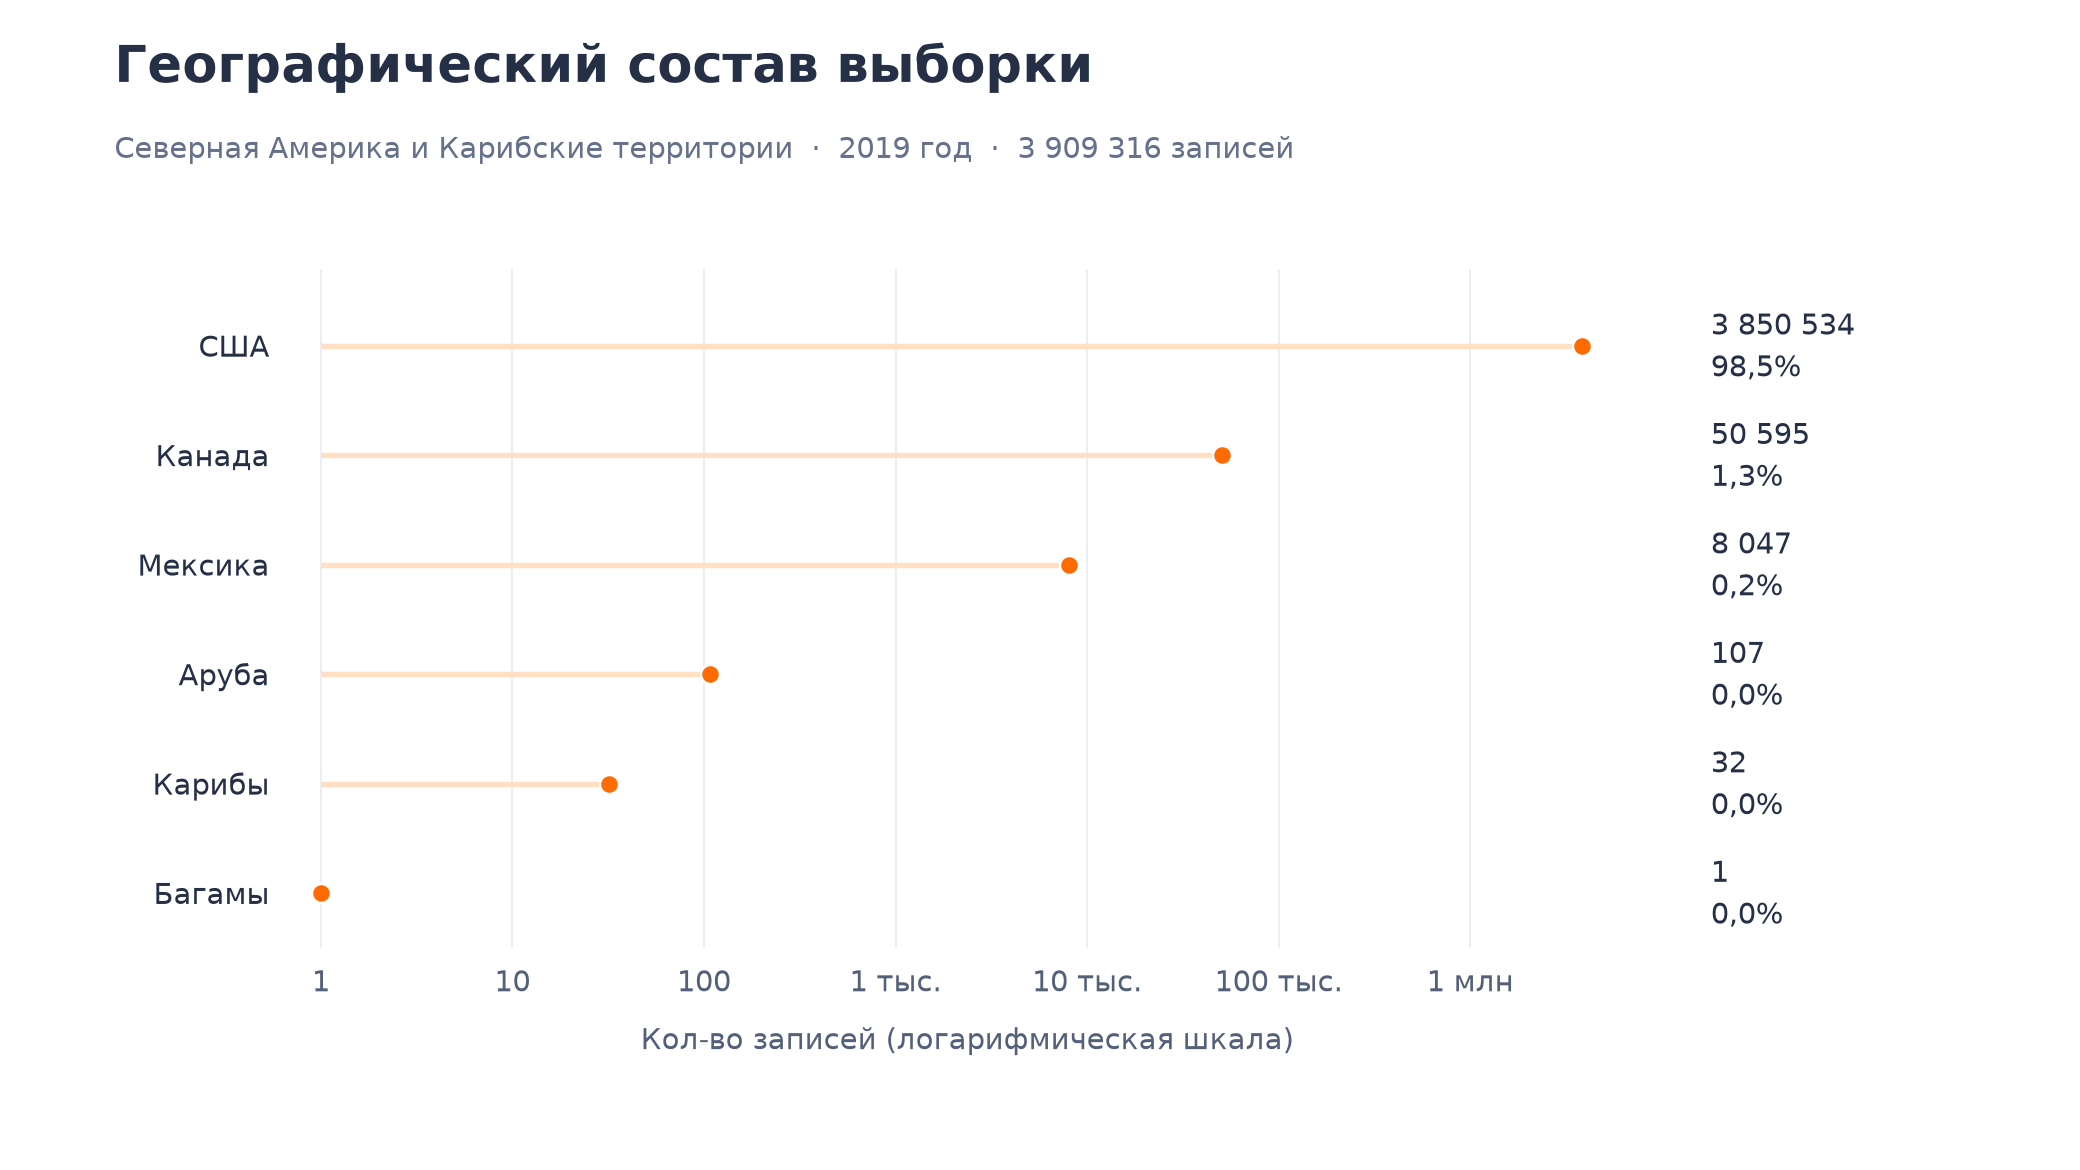

In [3]:
# Логарифмическая шкала показывает весь диапазон от одной до миллионов записей
fig, ax = plt.subplots(figsize=(16, 9))
fig.subplots_adjust(left=0.14, right=0.79, top=0.77, bottom=0.19)
y = range(len(countries))
ax.set_xscale("log")
ax.set_xlim(0.7, 8_000_000)
ax.set_ylim(len(countries) - 0.5, -0.7)
ax.set_axisbelow(True)
ax.set_xticks([1, 10, 100, 1000, 10000, 100000, 1000000],
              ["1", "10", "100", "1 тыс.", "10 тыс.", "100 тыс.", "1 млн"])
ax.minorticks_off()
ax.grid(axis="x", color="#E7EBF1", linewidth=0.9)
ax.hlines(y, 1, countries["rows"], color="#FFE0C4", linewidth=3, zorder=2)
ax.scatter(countries["rows"], y, s=110, color=ORANGE,
           edgecolor="white", linewidth=1.3, zorder=3)
ax.set_yticks(list(y), countries["name"])
ax.tick_params(axis="both", length=0, pad=12)
ax.set_xlabel("Кол-во записей (логарифмическая шкала)", labelpad=16)

# Кол-во записей и процент показываем на двух строках
for i, row in countries.iterrows():
    value = f"{int(row['rows']):,}".replace(",", " ")
    percent = f"{row['sample_percent']:.1f}".replace(".", ",")
    ax.text(1.05, i, f"{value}\n{percent}%", transform=ax.get_yaxis_transform(),
            va="center", fontsize=16, linespacing=1.5, clip_on=False)
fig.text(0.055, 0.93, "Географический состав выборки", fontsize=28, weight="bold")
fig.text(0.055, 0.865, "Северная Америка и Карибские территории  ·  2019 год  ·  3 909 316 записей",
         fontsize=16, color="#65718A")
# Сохраняем согласованный график для презентации и текста исследования
EXPORT = ROOT / "north_america" / "figures"
EXPORT.mkdir(parents=True, exist_ok=True)
fig.savefig(EXPORT / "01_geographic_composition.png", dpi=300, facecolor="white")
fig.savefig(EXPORT / "01_geographic_composition.svg", facecolor="white")

plt.show()


### Результат

В выборке 3 909 316 записей. На США приходится 3 850 534 записи, или 98,5%. Канада представлена 50 595 записями (1,3%), Мексика – 8 047 (0,2%). Совокупная доля Арубы, Карибов и Багам составляет около 0,0036%.

Объем наблюдений США примерно в 76 раз превышает канадский и в 479 раз – мексиканский. Географическое покрытие выраженно неравномерно. Логарифмическая шкала позволяет показать все группы одновременно; равные интервалы по оси соответствуют десятикратному изменению числа записей.

### Интерпретация

Результаты анализа объединенной выборки будут преимущественно определяться записями США. Региональную выборку следует описывать как набор с преобладанием американских аэропортов, а не как равномерное представление Северной Америки.

График показывает состав доступных наблюдений. Причины различий могут включать интенсивность движения, состав выбранных аэропортов и покрытие системы наблюдения. Их вклад по этому графику не установлен.

По Арубе имеется 107 записей, по Карибским Нидерландам – 32, по Багамам – одна. Таких объемов недостаточно для устойчивого сравнения редких событий между территориями. Отсутствие отмеченных уходов в малых группах не подтверждает отсутствие риска.

### Значение для подготовки базы

Записи всех территорий сохраняются. В следующих проверках результаты разделяются по странам и аэропортам. При оценке модели общие показатели дополняются показателями групп с указанием числа наблюдений и событий. Переносимость между странами требует отдельной проверки.

Географический дисбаланс характеризует покрытие базы и сам по себе не является ошибкой отдельной записи.

### Решение по составу аналитической выборки

Основная аналитическая выборка включает 55 аэропортов США и два аэропорта Канады: CYUL – Монреаль, CYOW – Оттава. Итог: 3 895 654 записи, из них 16 197 с отмеченным уходом на второй круг.

Багамы (1 запись), Аруба (107) и территория BES (32) исключаются из текущего анализа из-за недостаточного объема наблюдений для оценки редкого события. Мексика (8 047 записей, 33 ухода) исключается из основного эксперимента из-за ограниченного числа событий и незавершенной проверки национального нормативного контекста. Небольшая доля страны в общем наборе сама по себе не доказывает нерепрезентативность.

После исключения трех канадских аэропортов за пределами основной аналитической выборки остаются 13 662 записи. Они сохраняются в исходной базе для дальнейшего исследования. Сформирован отдельный CSV `data/derived/us_canada.csv`. Проверены кол-во строк, сохранность выбранных значений и неизменность исходника.

Первый график показывает состав исходной региональной выборки до ограничения. Последующие основные анализы выполняются для США и Канады с отдельной оценкой покрытия каждой страны.


## Основная выборка: США и Канада

Сформировано 3 895 654 записи, 16 197 с отмеченным уходом, 57 аэропортов. Значения не исправлены. За пределами текущего анализа остаются 13 662 исходные записи, они сохранены в региональном CSV.

Графики покрытия используют агрегаты аудита, отобранные по тем же кодам стран. Суммы проверяются по реестру сформированного CSV.


In [4]:
import json
import matplotlib.dates as mdates

selection = json.loads((ROOT / "north_america/reports/us_canada_selection.json").read_text(encoding="utf-8"))
airports = pd.read_csv(ROOT / "north_america/reports/airport_summary.csv")
airports = airports.loc[airports["airport_country"].isin(["USA", "CAN"])]
# CYUL – Монреаль, CYOW – Оттава
analysis_airports = airports.loc[(airports["airport_country"].eq("USA") & ~airports["airport"].isin(selection["excluded_us_airports"])) | (
    airports["airport_country"].eq("CAN") & airports["airport"].isin(["CYUL", "CYOW"]))]
assert int(analysis_airports["rows"].sum()) == selection["rows"]
assert int(analysis_airports["go_arounds"].sum()) == selection["go_arounds"]

def coverage(country, title, limit=None):
    group = airports.loc[airports["airport_country"].eq(country)].sort_values("rows", ascending=False)
    shown = group if limit is None else group.head(limit)
    fig, ax = plt.subplots(figsize=(16, max(9, len(shown) * 0.42 + 3)))
    fig.subplots_adjust(left=0.12, right=0.66, top=0.90 if len(shown) > 20 else 0.78, bottom=0.05 if len(shown) > 20 else 0.14)
    y = range(len(shown))
    ax.hlines(y, 0, shown["rows"], color="#FFE0C4", linewidth=3)
    ax.scatter(shown["rows"], y, s=80, color=ORANGE, zorder=3)
    ax.set_yticks(list(y), shown["airport"])
    ax.invert_yaxis()
    ax.set_xlim(0, shown["rows"].max() * 1.10)
    ax.grid(axis="x", color="#E7EBF1")
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.set_xlabel("Кол-во записей")
    for i, (_, row) in enumerate(shown.iterrows()):
        ax.text(1.28, i, f"{int(row['rows']):,}".replace(",", " "),
                transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=16)
        ax.text(1.55, i, str(int(row["go_arounds"])),
                transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=16)
    ax.text(1.28, 1.015 if len(shown) > 20 else 1.05, "Записей", transform=ax.transAxes, ha="right", fontsize=15)
    ax.text(1.55, 1.015 if len(shown) > 20 else 1.05, "С уходом", transform=ax.transAxes, ha="right", fontsize=15)
    fig.text(0.055, 0.975 if len(shown) > 20 else 0.93, title, fontsize=28, weight="bold")
    fig.text(0.055, 0.94 if len(shown) > 20 else 0.865, f"2019 год  ·  {len(group)} аэропортов  ·  показано {len(shown)}", fontsize=16, color="#65718A")
    return fig


## График 2. Покрытие аэропортов США

Показаны все 61 аэропорт США, упорядоченные по кол-ву записей. Столбец «С уходом» показывает кол-во записей с `has_ga=True`.

Коды на графике: KORD – Чикаго, KDFW – Даллас / Форт-Уэрт, KSFO – Сан-Франциско, KJFK – Нью-Йорк, KPHX – Финикс, KPHL – Филадельфия, KMSP – Миннеаполис / Сент-Пол, KLAS – Лас-Вегас, KSEA – Сиэтл, KEWR – Ньюарк, KLGA – Нью-Йорк, KBOS – Бостон, KIAD – Вашингтон, KATL – Атланта, KSAN – Сан-Диего.


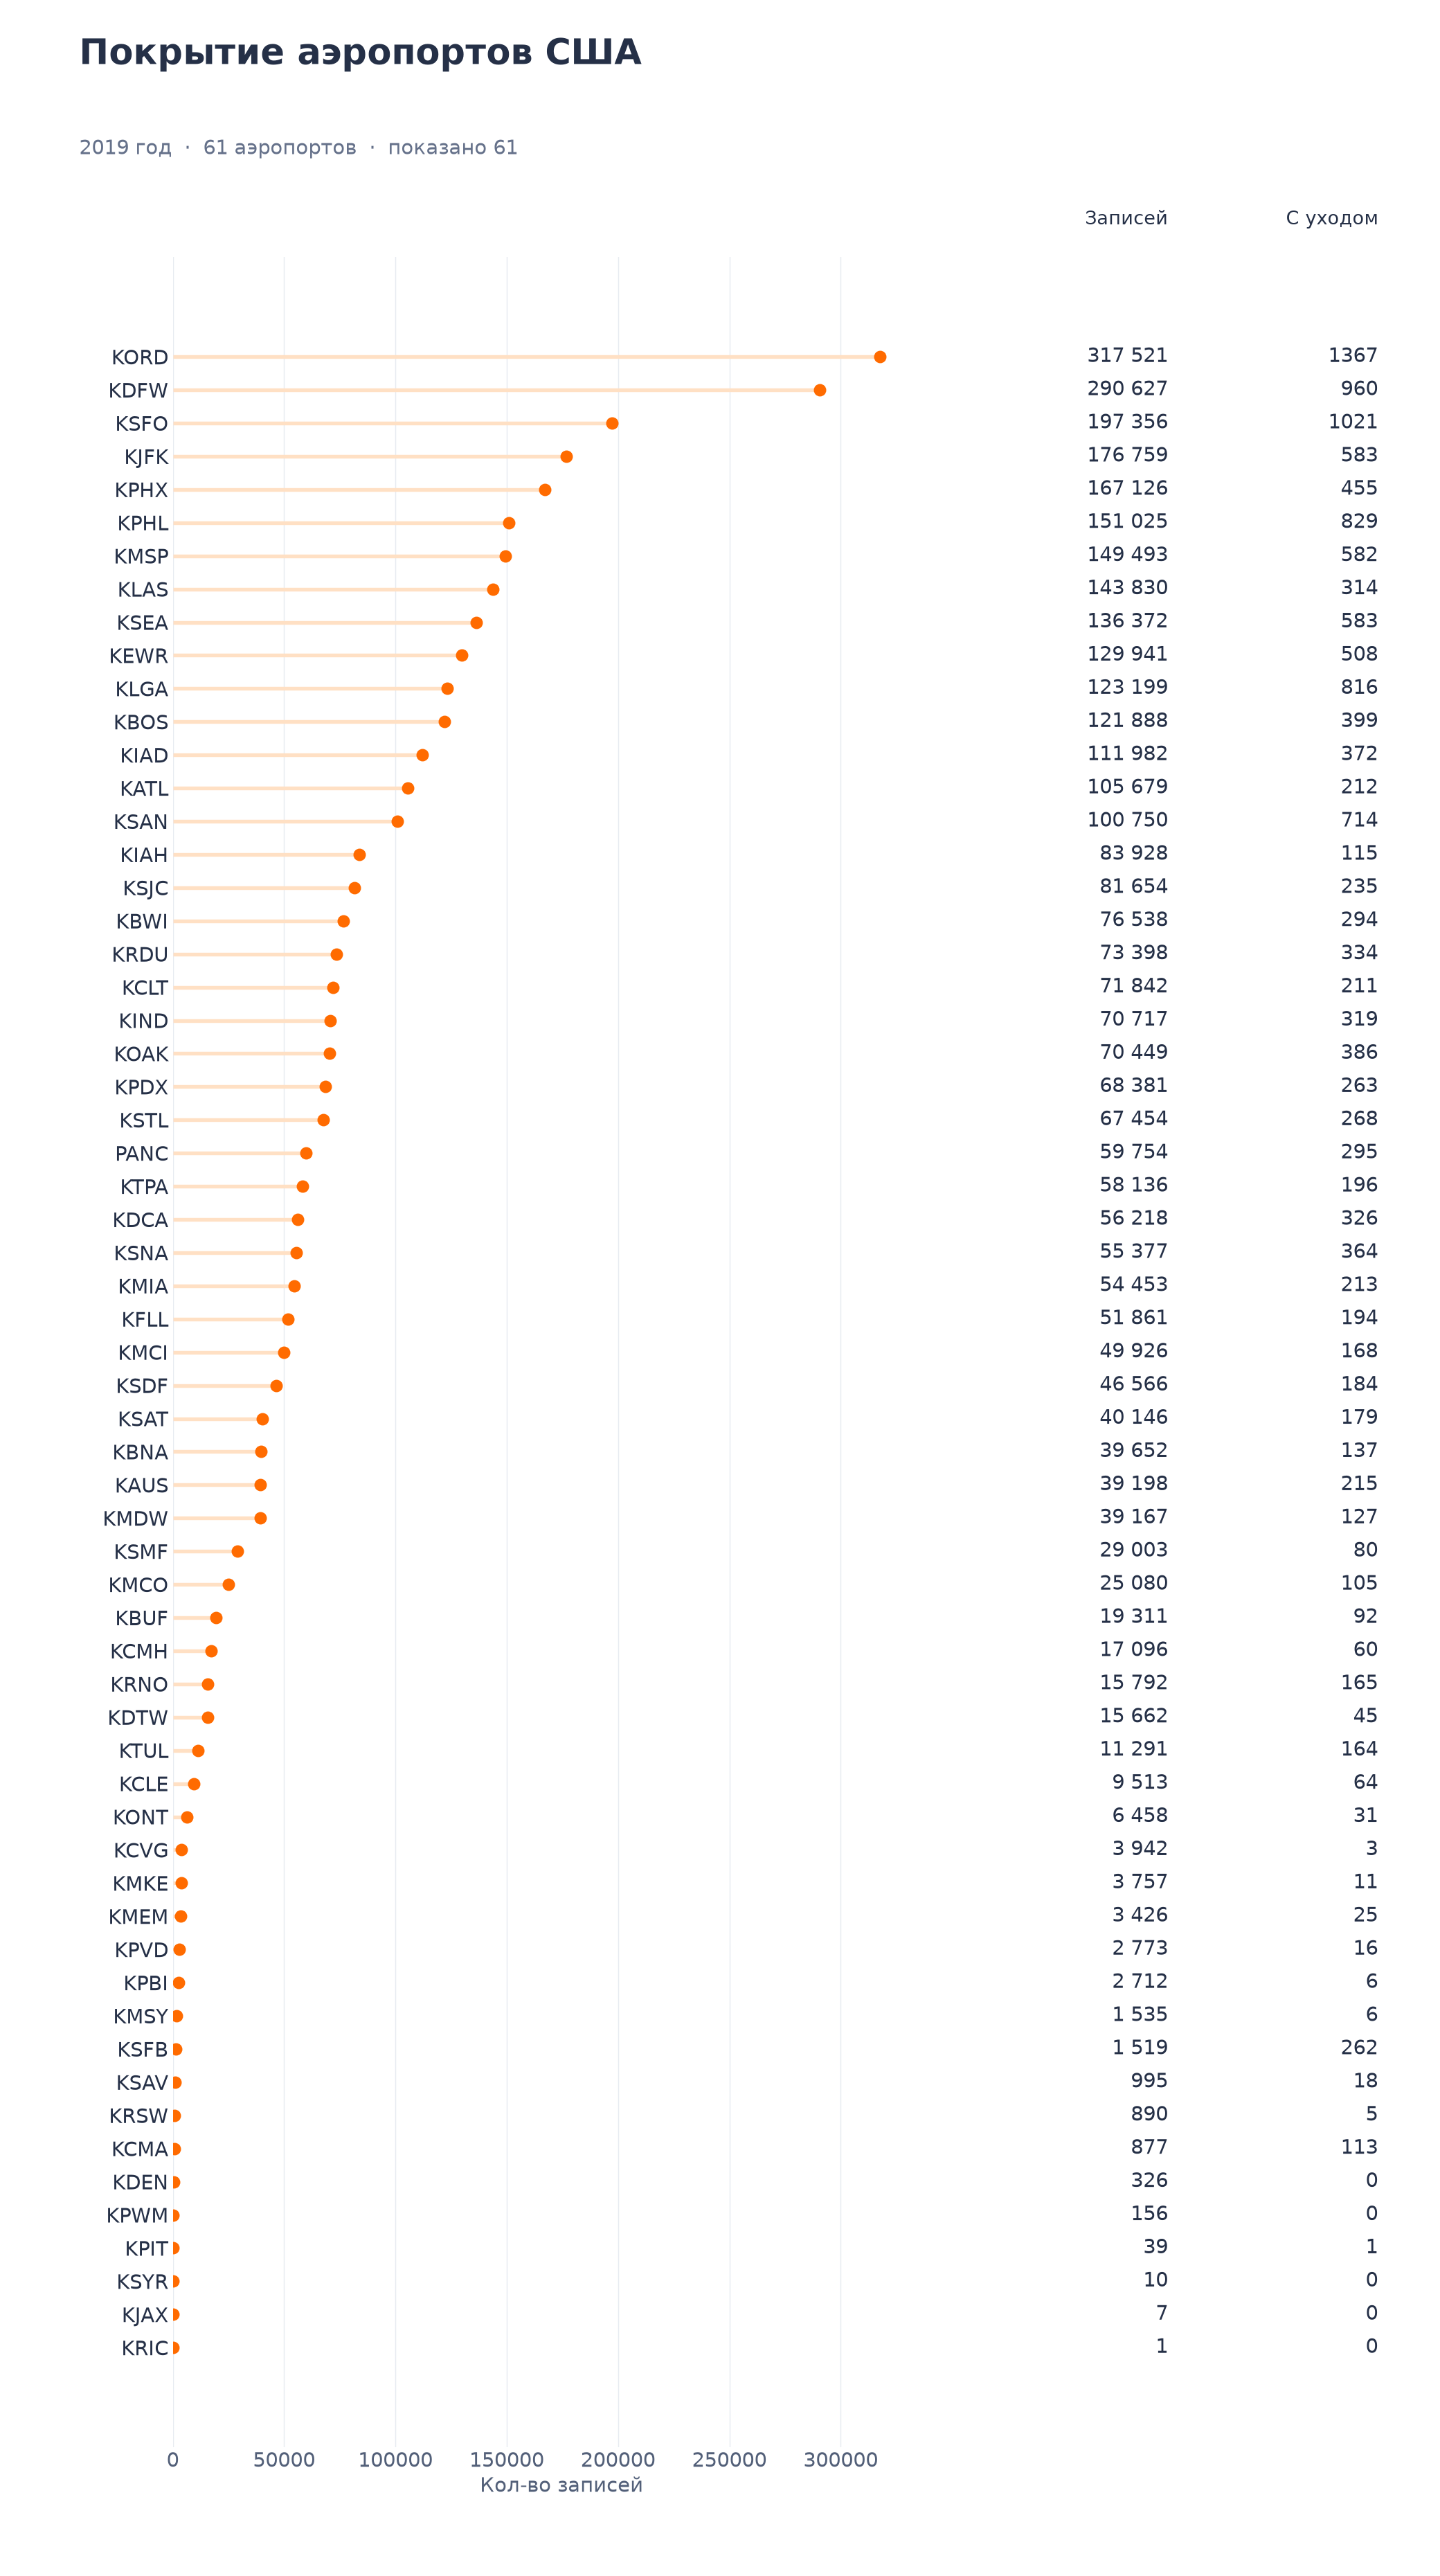

In [3]:
fig = coverage("USA", "Покрытие аэропортов США", limit=61)
# Сохраняем согласованный график покрытия аэропортов
EXPORT = ROOT / "north_america" / "figures"
EXPORT.mkdir(parents=True, exist_ok=True)
fig.savefig(EXPORT / "02_usa_airport_coverage.png", dpi=300, facecolor="white")
fig.savefig(EXPORT / "02_usa_airport_coverage.svg", facecolor="white")
plt.show()


США представлены 61 аэропортом. Наибольший объем наблюдений относится к KORD – Чикаго и KDFW – Даллас / Форт-Уэрт. Кол-во уходов зависит в том числе от объема наблюдений; этот график не позволяет сравнить вероятность ухода или установить его причины.

### Решение по малым группам США

Из основной аналитической выборки исключены KDEN – Денвер (326 записей), KPWM – Портленд, Мэн (156), KPIT – Питтсбург (39), KSYR – Сиракьюс (10), KJAX – Джэксонвилл (7), KRIC – Ричмонд (1). Всего 539 записей, включая один отмеченный уход в KPIT – Питтсбург. Исходные записи сохранены.

Отбор согласован как ограничение текущего эксперимента малыми объемами этих шести групп. Согласован допуск 0,2 п.п. по максимальному отклонению границы интервала Уилсона от выборочной частоты. Отсутствие уходов не является критерием исключения. График сохраняет все 61 исходную группу для прозрачности решения.

Для количественного критерия требуется заранее определить оцениваемую величину и допустимую неопределенность. При независимых наблюдениях и нуле событий односторонняя верхняя 95% граница биномиальной вероятности равна 1 − 0,05^(1/n). Для KDEN при n=326 это около 0,9%, для KPWM при n=156 – около 1,9%. Эти границы описывают неопределенность, но сами по себе не задают порог отбора. Зависимость полетов может снижать эффективный объем наблюдений.

KSFB – Санфорд (262 ухода из 1 519 записей) и KCMA – Камарильо (113 из 877) требуют проверки состава полетов и разметки. Они сохранены; повышенная доля уходов не является основанием удаления.


## График 3. Покрытие аэропортов Канады

Показаны все пять аэропортов до ограничения аналитической выборки. График сохранен как основание решения по составу данных. Линейная шкала отражает различие абсолютных объемов.


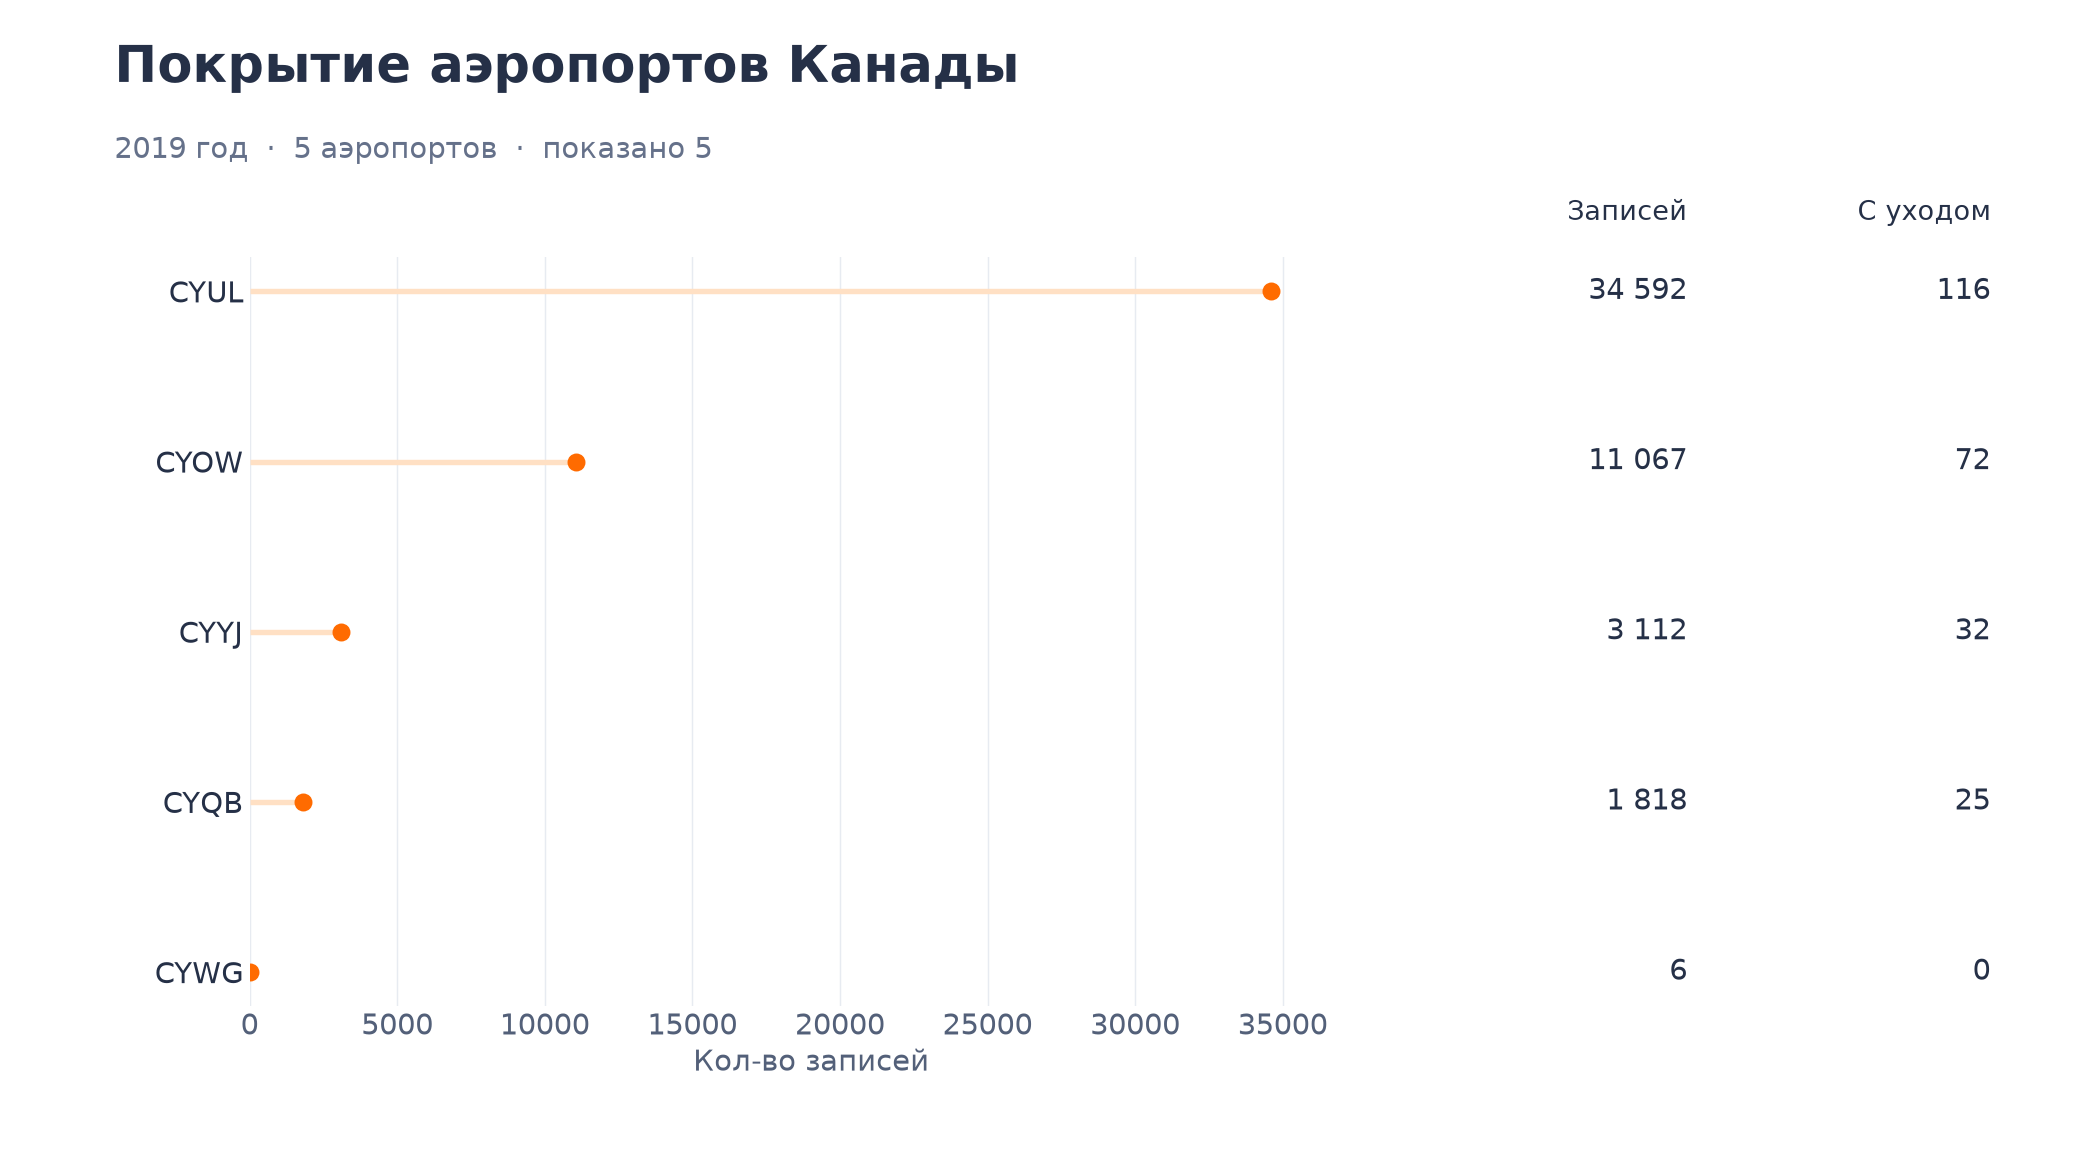

In [ ]:
fig = coverage("CAN", "Покрытие аэропортов Канады")
# Сохраняем согласованный график покрытия аэропортов
EXPORT = ROOT / "north_america" / "figures"
EXPORT.mkdir(parents=True, exist_ok=True)
fig.savefig(EXPORT / "03_canada_airport_coverage.png", dpi=300, facecolor="white")
fig.savefig(EXPORT / "03_canada_airport_coverage.svg", facecolor="white")
plt.show()


CYUL – Монреаль: 34 592 записи, 116 с отмеченным уходом. CYOW – Оттава: 11 067 записей, 72 с отмеченным уходом. Вместе они дают 45 659 записей и около 90,2% канадских наблюдений.

### Решение по аэропортам Канады

В основной аналитической выборке оставлены CYUL – Монреаль и CYOW – Оттава. Исключены:

| Аэропорт и город | Кол-во записей | С отмеченным уходом | Основание |
| --- | --- | --- | --- |
| CYYJ – Виктория | 3 112 | 32 | Меньший объем наблюдений и событий относительно выбранных аэропортов |
| CYQB – Квебек | 1 818 | 25 | Меньший объем наблюдений и событий относительно выбранных аэропортов |
| CYWG – Виннипег | 6 | 0 | Недостаточный объем наблюдений для оценки редкого события |

Отбор ограничивает текущий эксперимент двумя наиболее представленными канадскими аэропортами. Все три исключенные группы не проходят допуск 0,2 п.п. Решение ограничивает текущий анализ; исключенные записи не объявляются некорректными. В CYYJ – Виктория и CYQB – Квебек события зарегистрированы, но их отдельное исследование отложено.

Из текущего анализа исключены 4 936 канадских записей, включая 57 с отмеченным уходом. Исходные записи сохранены. Выводы канадской части относятся к CYUL – Монреаль и CYOW – Оттава; перенос на остальные аэропорты Канады требует отдельной проверки.

Города: [Монреаль](https://www.admtl.com/), [Оттава](https://www.yow.ca/), [Виктория](https://www.victoriaairport.com/), [Квебек](https://www.aeroportdequebec.com/), [Виннипег](https://www.waa.ca/).


# Обоснование состава аналитической выборки

## Критерий точности

Единица учета – запись о посадке, событие – наличие хотя бы одного отмеченного ухода.

$$
\widehat p_i=\frac{k_i}{n_i},\qquad
\Delta_i=\max(\widehat p_i-L_i,\;U_i-\widehat p_i),\qquad
\Delta_i\leq\varepsilon
$$

$[L_i,U_i]$ – двусторонний интервал Уилсона с номинальным уровнем доверия 95%, $z=\Phi^{-1}(0{,}975)$. $\varepsilon$ – допустимое абсолютное отклонение в единицах вероятности. В таблицах $\Delta$ выражено в процентных пунктах.

Согласован допуск $\varepsilon=0{,}002$ (0,2 п.п.), дата 07.10.2026. Интервалы рассчитаны для всех 74 аэропортов и шести стран и территорий, включая исключенные. Это выбранная абсолютная точность исследования. Параметр согласован после предварительного анализа, поэтому применение является ретроспективным.

Расчет предполагает независимость наблюдений и общую вероятность события внутри группы. Полнота периода, зависимость полетов и корректность разметки оцениваются отдельно. Низкая точность отдельной оценки не требует удаления записей из исходной базы.

## Исключенные страны и территории

| Группа | Записей | С уходом | Интервал Уилсона, % | $\Delta$, п.п. | Основание текущего решения |
| --- | ---: | ---: | --- | ---: | --- |
| Аруба (ABW) | 107 | 0 | 0.0000–3.4657 | 3.4657 | Критерий точности не выполнен; записи сохранены |
| Карибы (BES) | 32 | 0 | 0.0000–10.7179 | 10.7179 | Критерий точности не выполнен; записи сохранены |
| Багамы (BHS) | 1 | 0 | 0.0000–79.3451 | 79.3451 | Критерий точности не выполнен; одна запись |
| Мексика (MEX) | 8047 | 33 | 0.2922–0.5753 | 0.1652 | Национальный нормативный контекст не проверен; отдельное исследование отложено |

Малая доля страны в общей выборке не является самостоятельным доказательством нерепрезентативности. Исключение Мексики не объявляется следствием критерия точности. Национальные правила США и Канады на ее записи не переносятся.

## Исключенные аэропорты США и Канады

| ICAO – город | Записей | С уходом | Интервал Уилсона, % | $\Delta$, п.п. |
| --- | ---: | ---: | --- | ---: |
| CYQB – Квебек | 1818 | 25 | 0.9332–2.0222 | 0.6470 |
| CYWG – Виннипег | 6 | 0 | 0.0000–39.0334 | 39.0334 |
| CYYJ – Виктория | 3112 | 32 | 0.7293–1.4480 | 0.4197 |
| KDEN – Денвер | 326 | 0 | 0.0000–1.1646 | 1.1646 |
| KJAX – Джэксонвилл | 7 | 0 | 0.0000–35.4330 | 35.4330 |
| KPIT – Питтсбург | 39 | 1 | 0.4541–13.1810 | 10.6169 |
| KPWM – Портленд, Мэн | 156 | 0 | 0.0000–2.4033 | 2.4033 |
| KRIC – Ричмонд | 1 | 0 | 0.0000–79.3451 | 79.3451 |
| KSYR – Сиракьюс | 10 | 0 | 0.0000–27.7533 | 27.7533 |

Шесть аэропортов США исключены по согласованному ограничению состава эксперимента группами с малым объемом наблюдений. Отсутствие уходов не использовано как самостоятельный критерий. Все шесть групп не проходят согласованный допуск. Формальный расчет дополняет первоначальное решение, принятое до согласования параметра.

В Канаде текущий эксперимент ограничен CYUL – Монреаль и CYOW – Оттава, которые дают около 90,2% канадских наблюдений. CYYJ – Виктория и CYQB – Квебек имеют зарегистрированные события; меньший объем не доказывает их непригодность. CYWG – Виннипег представлен шестью записями. Все три группы не проходят согласованный допуск. Ограничение частотных оценок количественно подтверждено; исходные записи сохраняются.

Критерий рассчитан для всех аэропортов, включая оставленные. Из 57 текущих аэропортов 11 не проходят допуск; дополнительные исключения не применены. Порог не подбирается под прежний список исключений. Ограничение точности аэропортной оценки и отбор записей для общей модели рассматриваются отдельно.

## Сохранность и текущий состав

Исходный региональный CSV сохранен полностью. В аналитическом CSV 3 895 654 записи, 16 197 с отмеченным уходом, 55 аэропортов США и два аэропорта Канады. За пределами текущего анализа сохранены 13 662 записи.

Значения температуры и других полей не удалены и не исправлены. Высокие доли уходов в KSFB – Санфорд и KCMA – Камарильо не стали основанием исключения; группы оставлены для проверки.

Расчеты: `airport_precision.csv`, `country_precision.csv`. Повторение: `python north_america/scripts/assess_group_precision.py`.

## Оставленные группы с ограниченной точностью

| Аэропорт | Записей | С уходом | $\Delta$, п.п. |
| --- | ---: | ---: | ---: |
| KCMA | 877 | 113 | 2.3803 |
| KMEM | 3426 | 25 | 0.3453 |
| KMKE | 3757 | 11 | 0.2308 |
| KMSY | 1535 | 6 | 0.4593 |
| KONT | 6458 | 31 | 0.2005 |
| KPBI | 2712 | 6 | 0.2606 |
| KPVD | 2773 | 16 | 0.3583 |
| KRSW | 890 | 5 | 0.7465 |
| KSAV | 995 | 18 | 1.0324 |
| KSFB | 1519 | 262 | 1.9819 |
| KTUL | 11291 | 164 | 0.2378 |

Эти 11 групп остаются в аналитическом CSV. Отдельные частотные оценки не проходят допуск 0,2 п.п. Решение о дальнейшем использовании требуется отдельно.


## Таблица решений по аэропортам

Допуск: 0,2 п.п., двусторонний интервал Уилсона 95%. Значения показаны с округлением, критерий проверяется без округления. Исходные записи сохраняются.

| ICAO – город | Кол-во записей | С уходом | Доля уходов, % | Δ, п.п. | Решение | Основание | Примечания |
| --- | ---: | ---: | ---: | ---: | --- | --- | --- |
| CYQB – Квебек | 1818 | 25 | 1.375 | 0.647029 | Исключить | Δ превышает допуск 0,2 п.п. | Применено к CSV; первоначальное ограничение состава дополнено расчетом точности |
| CYWG – Виннипег | 6 | 0 | 0.000 | 39.033429 | Исключить | Δ превышает допуск 0,2 п.п. | Применено к CSV; первоначальное ограничение состава дополнено расчетом точности |
| CYYJ – Виктория | 3112 | 32 | 1.028 | 0.419703 | Исключить | Δ превышает допуск 0,2 п.п. | Применено к CSV; первоначальное ограничение состава дополнено расчетом точности |
| KCMA – Камарильо | 877 | 113 | 12.885 | 2.380288 | Временно исключить | Проверка назначения полетов, разметки и покрытия | Согласовано 08.10.2026; исследование в ноутбуке 03 |
| KDEN – Денвер | 326 | 0 | 0.000 | 1.164638 | Исключить | Δ превышает допуск 0,2 п.п. | Применено к CSV; первоначальное ограничение состава дополнено расчетом точности |
| KJAX – Джэксонвилл | 7 | 0 | 0.000 | 35.433044 | Исключить | Δ превышает допуск 0,2 п.п. | Применено к CSV; первоначальное ограничение состава дополнено расчетом точности |
| KMEM – Мемфис | 3426 | 25 | 0.730 | 0.345317 | Исключить | Δ превышает допуск 0,2 п.п. | Согласовано; применение к CSV после завершения всех решений |
| KMKE – Милуоки | 3757 | 11 | 0.293 | 0.230763 | Исключить | Δ превышает допуск 0,2 п.п. | Согласовано; применение к CSV после завершения всех решений |
| KMSY – Новый Орлеан | 1535 | 6 | 0.391 | 0.459298 | Исключить | Δ превышает допуск 0,2 п.п. | Согласовано; применение к CSV после завершения всех решений |
| KONT – Онтарио, Калифорния | 6458 | 31 | 0.480 | 0.200513 | Оставить | Допуск формально превышен; согласованное пограничное исключение | Согласовано; Δ = 0,200513 п.п., CSV без изменений |
| KPBI – Уэст-Палм-Бич | 2712 | 6 | 0.221 | 0.260625 | Исключить | Δ превышает допуск 0,2 п.п. | Согласовано; применение к CSV после завершения всех решений |
| KPIT – Питтсбург | 39 | 1 | 2.564 | 10.616888 | Исключить | Δ превышает допуск 0,2 п.п. | Применено к CSV; первоначальное ограничение состава дополнено расчетом точности |
| KPVD – Провиденс | 2773 | 16 | 0.577 | 0.358259 | Исключить | Δ превышает допуск 0,2 п.п. | Согласовано; применение к CSV после завершения всех решений |
| KPWM – Портленд, Мэн | 156 | 0 | 0.000 | 2.403293 | Исключить | Δ превышает допуск 0,2 п.п. | Применено к CSV; первоначальное ограничение состава дополнено расчетом точности |
| KRIC – Ричмонд | 1 | 0 | 0.000 | 79.345069 | Исключить | Δ превышает допуск 0,2 п.п. | Применено к CSV; первоначальное ограничение состава дополнено расчетом точности |
| KRSW – Форт-Майерс | 890 | 5 | 0.562 | 0.746540 | Исключить | Δ превышает допуск 0,2 п.п. | Согласовано; применение к CSV после завершения всех решений |
| KSAV – Саванна | 995 | 18 | 1.809 | 1.032396 | Исключить | Δ превышает допуск 0,2 п.п. | Согласовано; применение к CSV после завершения всех решений |
| KSFB – Санфорд | 1519 | 262 | 17.248 | 1.981914 | Временно исключить | Проверка назначения полетов, разметки и покрытия | Согласовано 08.10.2026; исследование в ноутбуке 03 |
| KSYR – Сиракьюс | 10 | 0 | 0.000 | 27.753280 | Исключить | Δ превышает допуск 0,2 п.п. | Применено к CSV; первоначальное ограничение состава дополнено расчетом точности |
| KTUL – Талса | 11291 | 164 | 1.452 | 0.237769 | Исключить | Δ превышает допуск 0,2 п.п. | Согласовано; применение к CSV после завершения всех решений |

Таблица фиксирует решения по точности аэропортных оценок и индивидуальные исключения из правила. Она не доказывает пригодность или непригодность группы для всех задач моделирования.


## Отдельное исследование аномалий.

KCMA – Камарильо и KSFB – Санфорд временно исключены из основной аналитической выборки до завершения проверки. Исходные записи сохранены. Решение согласовано 08 октября 2026 года.

Полный разбор перенесен в [ноутбук 03](03_airport_anomalies.ipynb).
